<a href="https://colab.research.google.com/github/riyalanjekar/XLY-Time-series-forecasting/blob/main/xly_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Project Name : Business Forecasting**

**Subject Code :** BBM122


#1. Introduction

The aim of this project is to develop and evaluate forecasting models for predicting the daily closing price of the Consumer Discretionary Select Sector Index (XLY) using historical market data and selected macroeconomic indicators. Two forecasting models ARIMA(statistical) and Random Forest(ML) will be developed and compared to the  Last-Value Baseline model;which is developed to provide a simple benchmark. Further Hyperparameter tuning and feature selection are performed to improve the performance of the Random Forest model. The forecasting performance of these models will be compared using evaluation metrics such as Root Squared Mean Error(RMSE) and Mean Abosulte Error(MAE); wherein lower values indicate better forecasting accuracy.

In [ ]:
pip install skforecast

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 567.8/567.8 kB 9.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [skforecast]


In [ ]:
pip install sktime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 17.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sktime]


In [ ]:
import pandas as pd
import numpy as np

import seaborn as sns
sns.set_theme(palette="colorblind")

import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

## Load data

In [ ]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Business Forecasting/Assessment/RIYA LANJEKAR-dataset.csv",
               parse_dates=["Date"],index_col="Date")
df.head()

,XLY,CPIAUCNS,FEDFUNDS,CL=F,GC=F,ZN=F,DX-Y.NYB
Date,,,,,,,
2020-01-02,60.276028,NaN,NaN,61.180000,1524.500000,128.625000,96.849998
2020-01-03,59.763081,NaN,NaN,63.049999,1549.199951,129.390625,96.839996
2020-01-06,59.929317,NaN,NaN,63.270000,1566.199951,129.250000,96.669998
2020-01-07,59.834332,NaN,NaN,62.700001,1571.800049,129.156250,96.980003
2020-01-08,60.014809,NaN,NaN,59.610001,1557.400024,128.765625,97.300003


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1258 entries, 2020-01-02 to 2024-12-31
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   XLY       1258 non-null   float64
 1   CPIAUCNS  41 non-null     float64
 2   FEDFUNDS  41 non-null     float64
 3   CL=F      1258 non-null   float64
 4   GC=F      1258 non-null   float64
 5   ZN=F      1258 non-null   float64
 6   DX-Y.NYB  1258 non-null   float64
dtypes: float64(7)
memory usage: 78.6 KB


In [ ]:
#Checking missing values
df.isnull().sum()

,0
XLY,0
CPIAUCNS,1217
FEDFUNDS,1217
CL=F,0
GC=F,0
ZN=F,0
DX-Y.NYB,0


In [ ]:
#Checking Outliers
for col in df.columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f"{col}: {len(outliers)} potential outliers")

XLY: 22 potential outliers
CPIAUCNS: 0 potential outliers
FEDFUNDS: 0 potential outliers
CL=F: 85 potential outliers
GC=F: 181 potential outliers
ZN=F: 0 potential outliers
DX-Y.NYB: 0 potential outliers


Note: There are 1217 missing values in CPIAUCNS and fFEDFUNDS column. Further there are also potential outliers in our target variable and predictors which were found using IQR method.

#2. EDA

##2.1. Train-Test split

In [ ]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.2, random_state=7, shuffle=False)

In [ ]:
train.shape, test.shape

((1006, 7), (252, 7))

## 2.2. Descriptive Statistcs

In [ ]:
# Check skewness and kurtosis
eda_summary = pd.DataFrame({
    'Mean': train.mean(),
    'Median': train.median(),
    'Std Dev': train.std(),
    'Min': train.min(),
    'Max': train.max(),
    'Skewness': train.skew(),
    'Kurtosis': train.kurtosis()
})

eda_summary

,Mean,Median,Std Dev,Min,Max,Skewness,Kurtosis
XLY,76.211952,76.693684,11.404277,41.534462,102.004295,-0.303261,0.053958
CPIAUCNS,283.001303,283.716000,18.244594,256.389000,307.789000,-0.103572,-1.558675
FEDFUNDS,1.763939,0.100000,2.183022,0.050000,5.330000,0.745449,-1.292174
CL=F,69.774652,72.869999,22.270018,-37.630001,123.699997,-0.331781,0.158928
GC=F,1828.163517,1828.549988,113.986535,1477.300049,2081.899902,-0.375625,-0.128542
ZN=F,125.282166,128.984375,11.043176,105.421875,140.328125,-0.176614,-1.538208
DX-Y.NYB,98.936909,98.820000,5.941735,89.440002,114.110001,0.247297,-0.912634


The descriptive statistics provide an overview of the distribution of each variable. The ranges of the variables vary widely and quite often so do the ranges of variability, which depend on the economic quantities they measure. For instance, the XLY and the US Dollar Index are in fairly tight ranges, while commodity prices, like oil, fluctuate widely. Some of these differences may indicate that there are unusual observations in these variables that need to be investigated further.


## 2.3. Time Series Visualisation

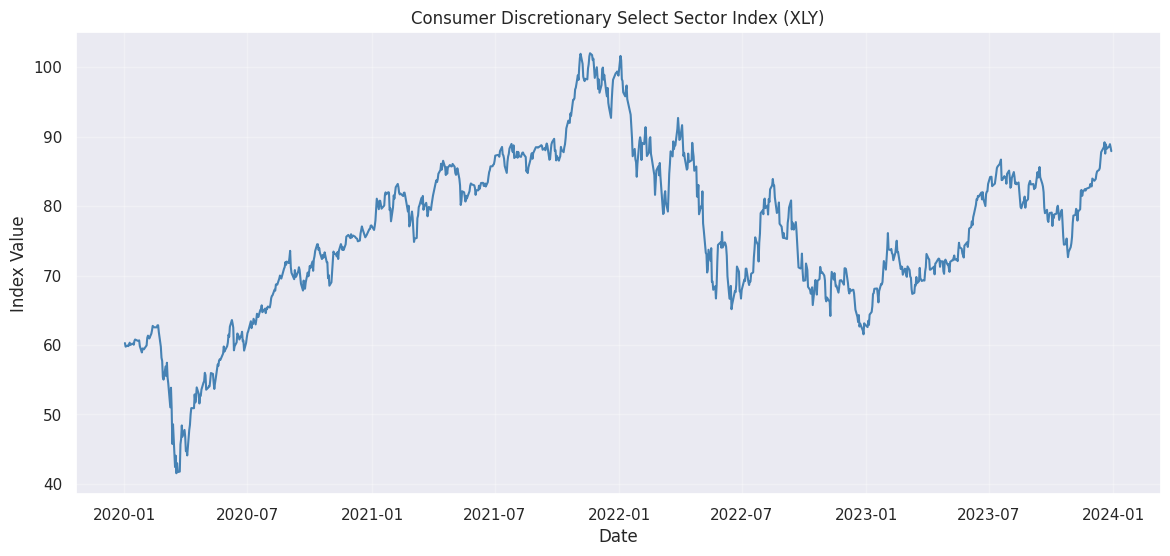

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(train.index,
         train["XLY"],
         color="steelblue",
         linewidth=1.5)

plt.title("Consumer Discretionary Select Sector Index (XLY)")
plt.xlabel("Date")
plt.ylabel("Index Value")

plt.grid(alpha=0.3)

plt.show()

The XLY series is not constant, but has definite trends over time. There is a significant decline in the first half of 2020, reflecting the impact of COVID-19 and disruption of global financial markets. The index then rises slowly through 2020 and 2021, drops in 2022, and slowly recovers towards the end of the series. The movements indicate that the series is not stationary and can be said that it has periods of high volatility in the market, which can be seen as a reason for further preprocessing in order to forecast the series.

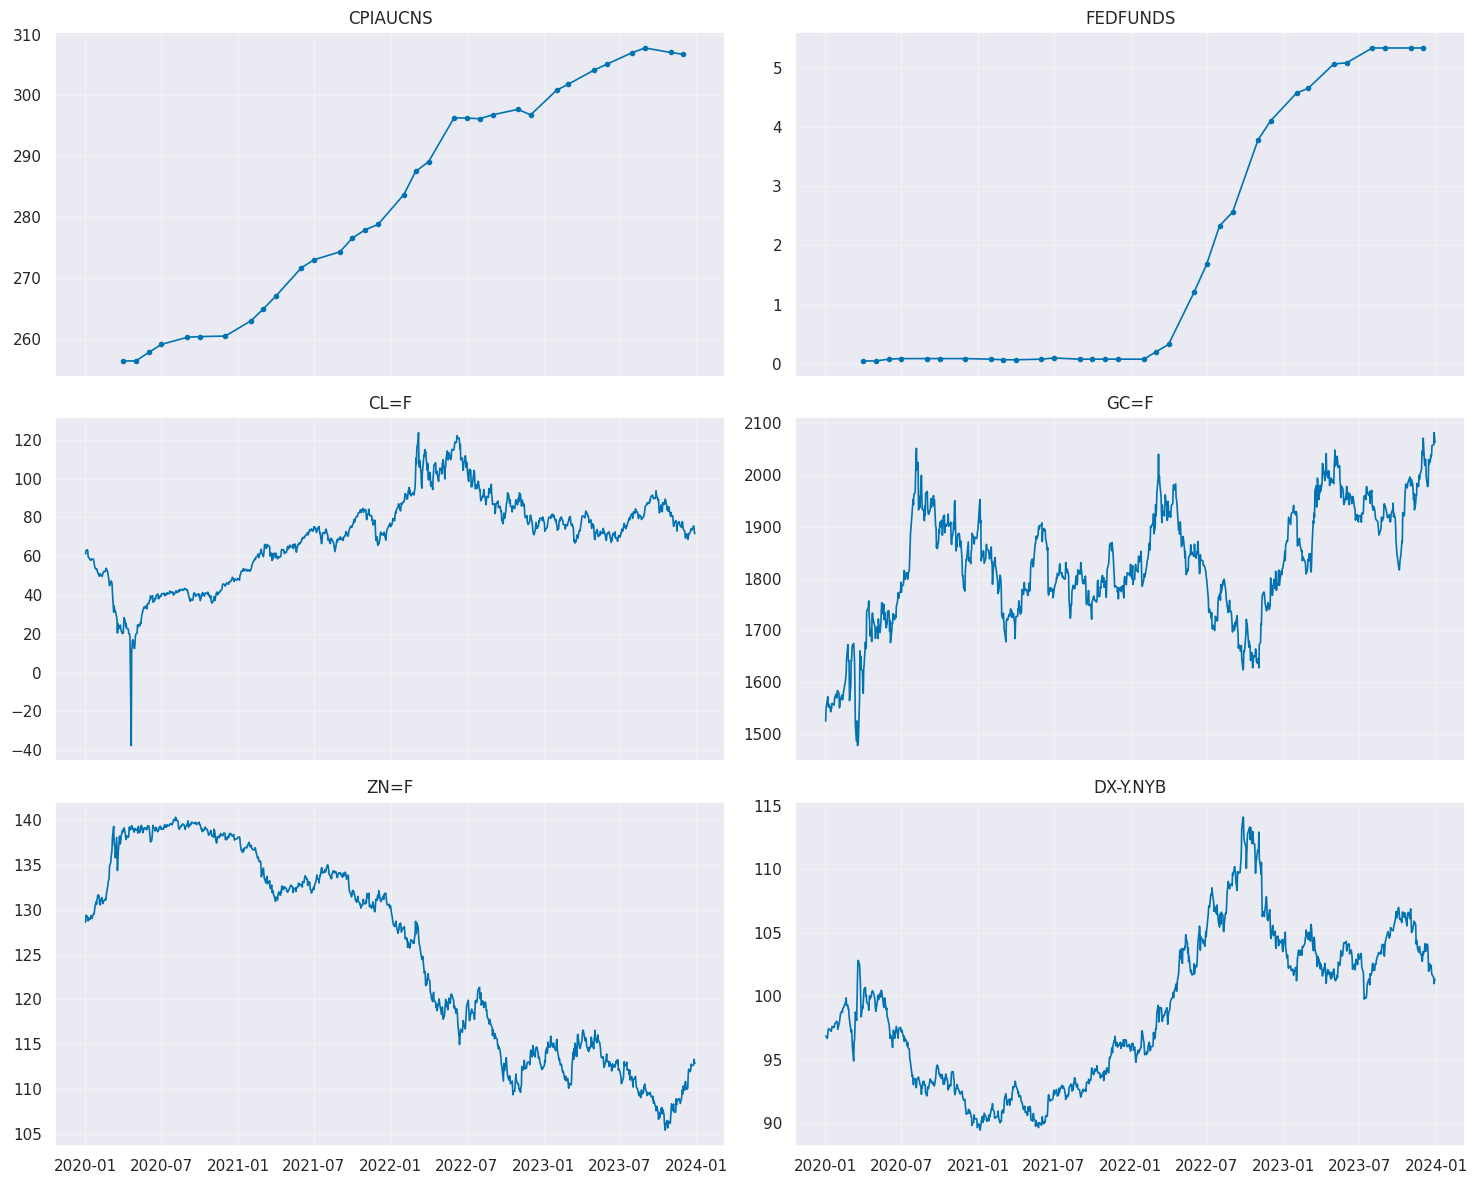

In [ ]:
exogenous = [
    "CPIAUCNS", "FEDFUNDS", "CL=F",
    "GC=F", "ZN=F", "DX-Y.NYB"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
axes = axes.flatten()

for ax, col in zip(axes, exogenous):
    series = train[col].dropna()

    ax.plot(
        series.index,
        series,
        linewidth=1.2,
        marker="o" if col in ["CPIAUCNS", "FEDFUNDS"] else None,
        markersize=3
    )

    ax.set_title(col)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The above figure shows the time series for the exogenous variables used in this study. Roughly speaking, crude oil futures (CL=F) have been highly volatile throughout the time under consideration, with a dramatic downward swing in 2020 that coincided with the impact of the COVID-19 pandemic on global crude oil markets. Gold futures (GC=F) move up and down over time, based on changes in investor demand during periods of economic uncertainty. The 10-Year Treasury Note futures (ZN=F) are in a general downward trend after 2021, while the US Dollar Index (DX-).NYB) displays several periods of appreciation and depreciation, suggesting fluctuations in the value of the US dollar. The following factors reflect economic conditions and were thus considered as variables that could predict the XLY index.

CPI and the federal Funds Rate contain sparse observations separated by missing daily values. The plots connect the available observations to show their movement over time. Missing values are addressed separately during preprocessing.

## 2.4. Correlation Analysis

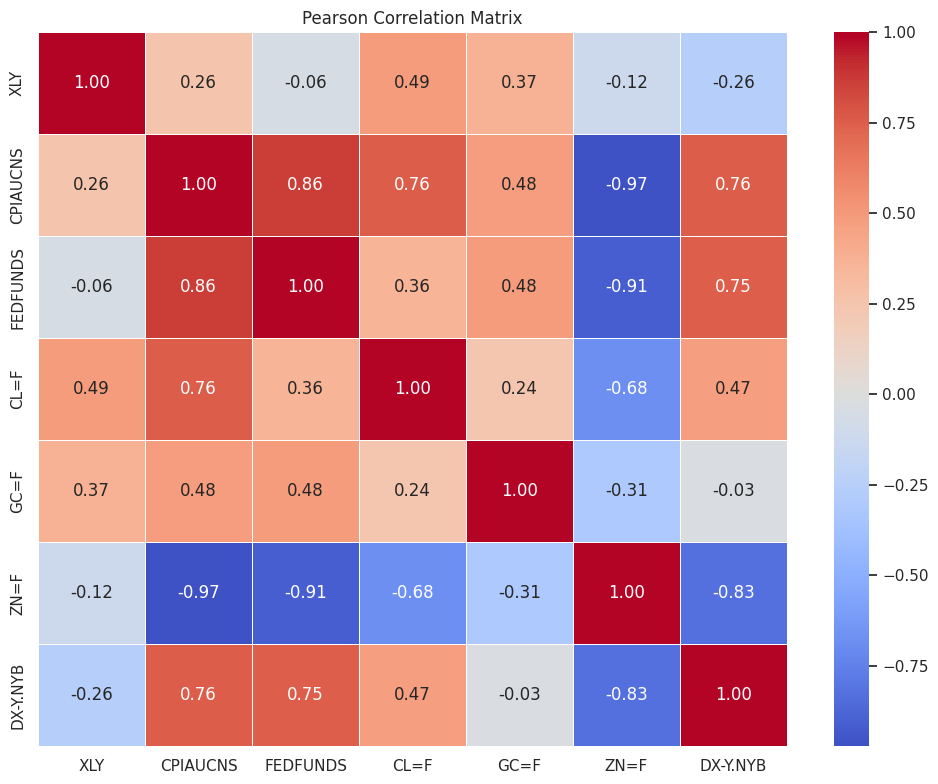

In [ ]:
# Correlation matrix of the training set
plt.figure(figsize=(10,8))

corr_matrix = train.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

To study the linear relationship between the selected macroeconomic indicators and the target variable (XLY), the Pearson's correlation matrix was used. Crude oil futures (CL=F) had the highest positive correlation with XLY (cor = 0.49); the second highest correlation with XLY was found with gold futures (GC=F) (cor = 0.37); the Consumer Price Index (CPIAUCNS) had the lowest positive correlation with XLY (cor = 0.26). The Federal Funds Rate (ZN=F), the 10-Year Treasury Note Futures and the US Dollar Index (DX-Y.) are of particular interest.NYB showed weak negative relationships with XLY, suggesting some nonlinear relationships with the target variable. These findings indicate that the exogenous variable alone cannot fully account for the time series variability of XLY, which reinforces the necessity to rely upon forecasting models which have the ability to learn from several exogenous variables at the same time.

## 2.5. STL Decomposition (XLY only)

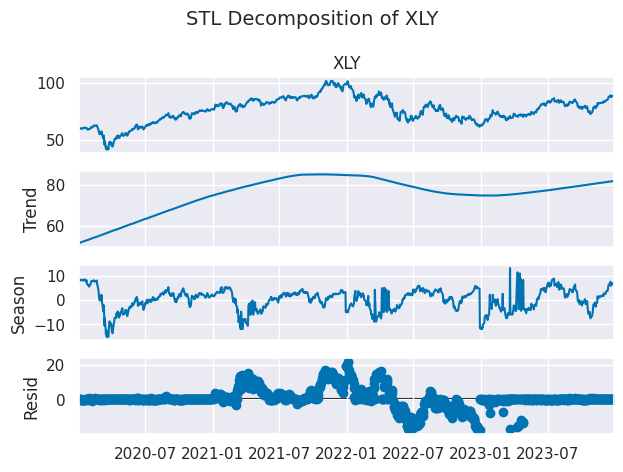

In [ ]:
from statsmodels.tsa.seasonal import STL

# period is the seasonal period
# seasonal is the window to estimate seasonality
# trend is the window to estimate trend
stl = STL(train["XLY"], period=252, seasonal=13, trend=253, robust=True)
result = stl.fit()
result.plot()
plt.suptitle("STL Decomposition of XLY", fontsize=14)
plt.tight_layout()
plt.show()

The trend component indicates that the overall trend of the index is upward from early 2020 to late 2021 and downward in 2022, but upward toward the end. This pattern mirrors that of the time series shown initially. The seasonal component does not repeat distinctly and considerably around zero, indicating that seasonality is not a major strong influence over the daily stock prices. The residual term is obtained by subtracting the trend and seasonality from the irregular fluctuations. The larger the residuals, the more volatile the market during 2021-2022. Overall, the decomposition indicates that the XLY index exhibits limited seasonal influence and is primarily shaped by long-term trends and occasional market fluctuations.

## 2.6. ADF Test

In [ ]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train["XLY"])

print("ADF Statistic:", round(adf_result[0],4))
print("p-value:", round(adf_result[1],4))

print("\nCritical Values")

for key, value in adf_result[4].items():
    print(f"{key}: {value:.4f}")

ADF Statistic: -1.9725
p-value: 0.2987

Critical Values
1%: -3.4369
5%: -2.8644
10%: -2.5683


/tmp/ipykernel_1409/3876151283.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train["XLY"])


In [ ]:
if adf_result[1] < 0.05:
    print("\nConclusion: Reject H0. The series is stationary.")
else:
    print("\nConclusion: Fail to reject H0. The series is non-stationary.")


Conclusion: Fail to reject H0. The series is non-stationary.


The target series was tested for stationarity using the Augmented Dickey-Fuller (ADF) test. The results showed that the original XLY series was not stationary and had a trend. First-order differencing was used in pre-processing to meet the ARIMA modelling assumptions and to enhance the forecasting ability of the model

## 2.7. ACF & PACF

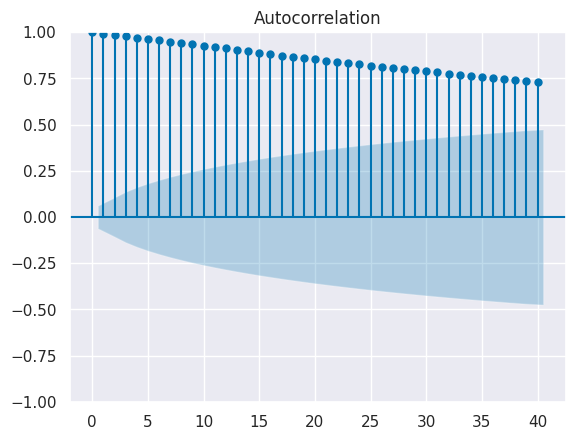

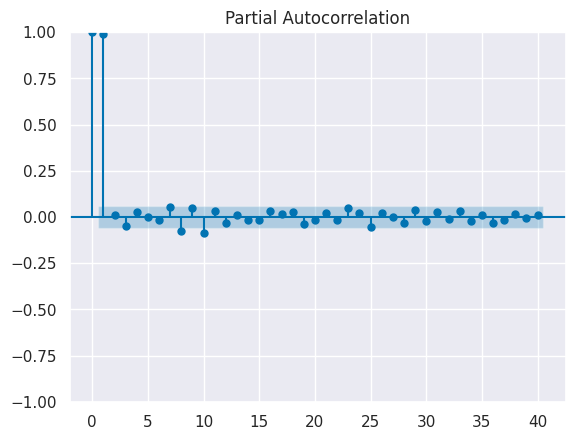

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

_ = plot_acf(train['XLY'], lags=40)
_ = plot_pacf(train['XLY'], lags=40)

The ACF shows a slow and gradual decline, with significant positive autocorrelations remaining across many lags. This means that successive observations are highly correlated with each other and it would appear that the series is non-stationary. The PACF, on the other hand, displays one high peak at lag 1, with the other lags lying within the confidence intervals, suggesting that the highest correlation is with the previous period's observation.

#3. Preprocessing



## 3.1. Imputing Missing Values

In [ ]:
# Forward fill and backward fill macroeconomic variables

# Training set
train["CPIAUCNS"] = train["CPIAUCNS"].ffill().bfill()
train["FEDFUNDS"] = train["FEDFUNDS"].ffill().bfill()

# Test set
test["CPIAUCNS"] = test["CPIAUCNS"].ffill().bfill()
test["FEDFUNDS"] = test["FEDFUNDS"].ffill().bfill()

In [ ]:
print("Train missing values:")
print(train.isnull().sum())

print("\nTest missing values:")
print(test.isnull().sum())

Train missing values:
XLY         0
CPIAUCNS    0
FEDFUNDS    0
CL=F        0
GC=F        0
ZN=F        0
DX-Y.NYB    0
dtype: int64

Test missing values:
XLY         0
CPIAUCNS    0
FEDFUNDS    0
CL=F        0
GC=F        0
ZN=F        0
DX-Y.NYB    0
dtype: int64


The CPI (CPIAUCNS) and Federal Funds Rate (FEDFUNDS) variables were found to have missing values. The time series were filled with missing values in the training and test sets separately, in a forward-filled and a backward-filled manner to maintain the time series order. Forward-fill means that missing data is filled with the latest available data, and backward-fill only applies to fill in missing values at the start of the series. This method is used to prevent introducing unrealistic values, and to ensure that all variables are complete before model development. When the data data sets were imputed, there were no missing data in either the training or test sets.

### Putting the dataset back together.

In [ ]:
full_data = pd.concat([train, test])
full_data.head()

,XLY,CPIAUCNS,FEDFUNDS,CL=F,GC=F,ZN=F,DX-Y.NYB
Date,,,,,,,
2020-01-02,60.276028,256.389,0.05,61.180000,1524.500000,128.625000,96.849998
2020-01-03,59.763081,256.389,0.05,63.049999,1549.199951,129.390625,96.839996
2020-01-06,59.929317,256.389,0.05,63.270000,1566.199951,129.250000,96.669998
2020-01-07,59.834332,256.389,0.05,62.700001,1571.800049,129.156250,96.980003
2020-01-08,60.014809,256.389,0.05,59.610001,1557.400024,128.765625,97.300003


In [ ]:
# Check missing values after recombining
print(full_data.isnull().sum())

XLY         0
CPIAUCNS    0
FEDFUNDS    0
CL=F        0
GC=F        0
ZN=F        0
DX-Y.NYB    0
dtype: int64


## 3.2. Outlier treatment

In [ ]:
# IQR-based outlier treatment for CL=F only

Q1 = full_data["CL=F"].quantile(0.25)
Q3 = full_data["CL=F"].quantile(0.75)
IQR = Q3 - Q1

lower_clf = Q1 - 1.5 * IQR
upper_clf = Q3 + 1.5 * IQR

print(f"CL=F lower bound: {lower_clf:.2f}")
print(f"CL=F upper bound: {upper_clf:.2f}")

CL=F lower bound: 34.08
CL=F upper bound: 110.57


In [ ]:
# Clip CL=F values to IQR bounds
full_data["CL=F"] = full_data["CL=F"].clip(
    lower=lower_clf,
    upper=upper_clf
)

print(f"New CL=F minimum: {full_data['CL=F'].min():.2f}")
print(f"New CL=F maximum: {full_data['CL=F'].max():.2f}")

New CL=F minimum: 34.08
New CL=F maximum: 110.57


Using the Interquartile Range (IQR) method, some potential outliers were detected in variables. But that's not the case for every extreme observation, for many of those are simply market movements, not data errors. Outlier treatment was done only to crude oil futures (CL=F) as these prices had the worst extreme values, such as the sudden drop of crude oil prices in 2020. Any values outside of the calculated IQR spread were trimmed to the lower and upper boundaries. This provided a way to minimize the effect of the most extreme oil price changes and maintained the shape of the data set.

## 3.3. Stationarizing the series

In [ ]:
from sktime.transformations.series.difference import Differencer

transformer = Differencer(lags=[1])

full_data["XLY_diff"] = transformer.fit_transform(full_data["XLY"])

full_data = full_data.dropna()

full_data_model = full_data.reset_index(drop=True)

# 4. Baseline Model

In [ ]:
# Target and predictors
y = full_data_model["XLY_diff"]
X = full_data_model.drop(columns=["XLY", "XLY_diff"])

##Setup Timeseriesfold

In [ ]:
from skforecast.recursive import ForecasterEquivalentDate
from skforecast.model_selection._validation import backtesting_forecaster
from sklearn.metrics import root_mean_squared_error

from skforecast.exceptions import IgnoredArgumentWarning
warnings.filterwarnings("ignore", category=IgnoredArgumentWarning)
from skforecast.exceptions import LongTrainingWarning
warnings.simplefilter('ignore', category=LongTrainingWarning)

In [ ]:
from skforecast.model_selection import TimeSeriesFold

cv = TimeSeriesFold(
         steps=1,
         initial_train_size = int(len(full_data_model) * 0.8),
         refit=False,
         fixed_train_size=False
     )

last_value_forecaster = ForecasterEquivalentDate(offset=1, n_offsets=1)

results_lv, predictions_backtest = backtesting_forecaster(
                                   forecaster=last_value_forecaster,
                                   y=full_data_model["XLY_diff"],
                                   cv=cv,
                                   metric=[root_mean_squared_error,
                                           'mean_absolute_error'],
                                   n_jobs='auto',
                                   verbose=False,
                                   show_progress=True
                               )
results_lv.index = ["Last Value Baseline"]
results_lv

  0%|          | 0/252 [00:00<?, ?it/s]

,root_mean_squared_error,mean_absolute_error
Last Value Baseline,1.57054,1.206563


The Last Value Baseline was used as a benchmark for comparing more advanced forecasting models. The method predicts the next observation will be the same as the most recent value observed. The Mean Absolute Error (MAE) of the model was 1.20 (approx.) and Root Mean Squared Error (RMSE) was 1.57 (approx.). The relatively small errors suggest that the index of XLY tends to move slowly over time and that it is not easy to beat a persistence-based forecast. Thus, any forecasting model must have smaller errors than this minimum error to prove it adds value to the prediction.

# 5. Model Development and Evaluation

## 5.1 ARIMA

In [ ]:
from skforecast.stats._arima import Arima

y = full_data_model["XLY_diff"]

auto_arima = Arima(
    order=None,                 # None enables AutoARIMA
    seasonal_order=(0, 0, 0),    # non-seasonal ARIMA
    start_p=0,
    start_q=0,
    max_p=5,
    max_q=5,
    max_d=2,
    ic="aic",
    seasonal=False,
    test="adf",
    stepwise=True,              # faster than trying all combinations
    trace=True
)

auto_arima.fit(
    y=full_data_model["XLY_diff"],
    suppress_warnings=True
)

auto_arima


Fitting models using approximations...

 ARIMA(p,d,q)(P,D,Q)[m]                     : aic
 ------------------------------------------------
 ARIMA(0,0,0) with non-zero mean : 4035.2892
 ARIMA(0,0,0) with non-zero mean : 4035.2892
 ARIMA(1,0,0) with non-zero mean : 4037.7249
 ARIMA(0,0,1) with non-zero mean : 4036.7683
 ARIMA(0,0,0) with zero mean     : 4034.7177
 ARIMA(1,0,1) with non-zero mean : 4038.4564

Now re-fitting the best model(s) without approximations...
 ARIMA(0,0,0) with zero mean     : 4034.7177

Best model found: ARIMA(0,0,0)(0,0,0)[1] with aic: 4034.7177376857744



AutoArima(0,0,0)

In [ ]:
auto_arima.summary()

ARIMA Model Summary
Model     : AutoArima(0,0,0)
Method    : ARIMA(0,0,0)(0,0,0)[1]
Converged : True

Coefficients:
------------------------------------------------------------

Model fit statistics:
  sigma^2:             1.444526
  Log-likelihood:      -2016.36
  AIC:                 4034.72
  BIC:                 4039.86

Residual statistics:
  Mean:                0.040490
  Std Dev:             1.201680
  MAE:                 0.899266
  RMSE:                1.201884

Time Series Summary Statistics:
Number of observations: 1258
  Mean:                 0.0405
  Std Dev:              1.2017
  Min:                  -6.1554
  25%:                  -0.5670
  Median:               0.1041
  75%:                  0.7628
  Max:                  4.6906


### Model Evaluation

In [ ]:
from skforecast.model_selection import TimeSeriesFold
from skforecast.recursive import ForecasterStats
from skforecast.model_selection._validation import backtesting_stats

cv = TimeSeriesFold(
         steps=1,
         initial_train_size = int(len(full_data_model) * 0.8),
         refit=False,
         fixed_train_size=False
     )

arima_forecaster = ForecasterStats(estimator=auto_arima)

In [ ]:
results_arima, predictions_backtest = backtesting_stats(
                                   forecaster=arima_forecaster,
                                   y=full_data_model["XLY_diff"],
                                   cv=cv,
                                   metric=[root_mean_squared_error,
                                           'mean_absolute_error'],
                                   n_jobs='auto',
                                   verbose=False,
                                   show_progress=True
                               )
results_arima.index = ["ARIMA"]
results_arima


Fitting models using approximations...

 ARIMA(p,d,q)(P,D,Q)[m]                     : aic
 ------------------------------------------------
 ARIMA(0,0,0) with non-zero mean : 3261.1789
 ARIMA(0,0,0) with non-zero mean : 3261.1789
 ARIMA(1,0,0) with non-zero mean : 3263.3922
 ARIMA(0,0,1) with non-zero mean : 3262.4673
 ARIMA(0,0,0) with zero mean     : 3259.6875
 ARIMA(1,0,1) with non-zero mean : 3263.6842

Now re-fitting the best model(s) without approximations...
 ARIMA(0,0,0) with zero mean     : 3259.6875

Best model found: ARIMA(0,0,0)(0,0,0)[1] with aic: 3259.6875205047486



  0%|          | 0/252 [00:00<?, ?it/s]


Fitting models using approximations...

 ARIMA(p,d,q)(P,D,Q)[m]                     : aic
 ------------------------------------------------
 ARIMA(0,0,0) with non-zero mean : 3263.8931
 ARIMA(0,0,0) with non-zero mean : 3263.8931
 ARIMA(1,0,0) with non-zero mean : 3266.1242
 ARIMA(0,0,1) with non-zero mean : 3265.1980
 ARIMA(0,0,0) with zero mean     : 3262.3719
 ARIMA(1,0,1) with non-zero mean : 3266.4165

Now re-fitting the best model(s) without approximations...
 ARIMA(0,0,0) with zero mean     : 3262.3719

Best model found: ARIMA(0,0,0)(0,0,0)[1] with aic: 3262.3719200610217


Fitting models using approximations...

 ARIMA(p,d,q)(P,D,Q)[m]                     : aic
 ------------------------------------------------
 ARIMA(0,0,0) with non-zero mean : 3268.2686
 ARIMA(0,0,0) with non-zero mean : 3268.2686
 ARIMA(1,0,0) with non-zero mean : 3270.5558
 ARIMA(0,0,1) with non-zero mean : 3269.6249
 ARIMA(0,0,0) with zero mean     : 3266.6858
 ARIMA(1,0,1) with non-zero mean : 3270.8599



,root_mean_squared_error,mean_absolute_error
ARIMA,1.119569,0.861978


The ARIMA model performed better than the Last Value Baseline on both the MAE and RMSE with values of around 0.87 and 1.13 respectively. This means that the patterns in time, which are short-term, were captured by ARIMA and not by the baseline model. The forecasting errors presented, shows that the errors are lower in the presence of historical autocorrelation, indicating that the historical autocorrelation has given more accurate forecasts.

### Model Plot

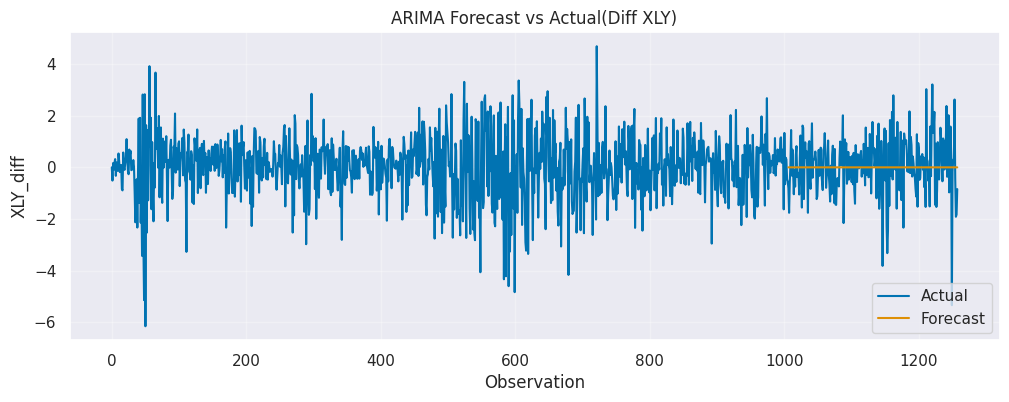

In [ ]:
tdf = pd.DataFrame({
    "Actual": full_data_model["XLY_diff"],
    "Forecast": predictions_backtest["pred"]
})

tdf.plot(figsize=(12, 4))

plt.title("ARIMA Forecast vs Actual(Diff XLY)")
plt.xlabel("Observation")
plt.ylabel("XLY_diff")
plt.grid(alpha=0.3)
plt.show()

The forecast is very close to the actual movement of a differenced XLY series during most of the evaluation period. At times when the market is undergoing rapid price changes, it is hard to predict small deviations, so a linear statistical model is not suitable. In general, we can say that the forecast is doing a good job of representing the overall trend and short-term fluctuations.

## 5.2 Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from skforecast.recursive import ForecasterRecursive
from skforecast.model_selection import grid_search_forecaster

y = full_data_model["XLY_diff"]

exog_features = full_data_model.columns.to_list()
exog_features.remove("XLY")
exog_features.remove("XLY_diff")

exog = full_data_model[exog_features]

In [ ]:
forecaster = ForecasterRecursive(
    estimator=RandomForestRegressor(random_state = 7),
    lags=24
)

lags_grid = [7, 14, 24]

# Hyperparameter search space
hp_grid = {
    "n_estimators": [100, 200,300],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}


cv_hp_search = TimeSeriesFold(
    steps=1,
    initial_train_size=int(len(full_data_model) * 0.8),
    refit=False,
    fixed_train_size=False
)

results_search = grid_search_forecaster(
    forecaster=forecaster,
    y=y,
    exog=exog,
    cv=cv_hp_search,
    param_grid=hp_grid,
    lags_grid=lags_grid,
    metric="mean_absolute_error",
    return_best=True,

)

results_search.head(10)

lags grid:   0%|          | 0/3 [00:00<?, ?it/s]

params grid:   0%|          | 0/81 [00:00<?, ?it/s]

params grid:   0%|          | 0/81 [00:00<?, ?it/s]

params grid:   0%|          | 0/81 [00:00<?, ?it/s]

,lags,lags_label,params,mean_absolute_error,max_depth,min_samples_leaf,min_samples_split,n_estimators
0,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","{'max_depth': 5, 'min_samples_leaf': 4, 'min_s...",0.872376,5.0,4.0,10.0,100.0
1,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","{'max_depth': 5, 'min_samples_leaf': 4, 'min_s...",0.872399,5.0,4.0,2.0,100.0
2,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","{'max_depth': 5, 'min_samples_leaf': 4, 'min_s...",0.872399,5.0,4.0,5.0,100.0
3,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","{'max_depth': 5, 'min_samples_leaf': 4, 'min_s...",0.875075,5.0,4.0,10.0,200.0
4,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","{'max_depth': 5, 'min_samples_leaf': 4, 'min_s...",0.875425,5.0,4.0,2.0,200.0
5,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","{'max_depth': 5, 'min_samples_leaf': 4, 'min_s...",0.875425,5.0,4.0,5.0,200.0
6,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","{'max_depth': 5, 'min_samples_leaf': 4, 'min_s...",0.875942,5.0,4.0,10.0,300.0
7,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","{'max_depth': 5, 'min_samples_leaf': 4, 'min_s...",0.875943,5.0,4.0,2.0,300.0
8,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","{'max_depth': 5, 'min_samples_leaf': 4, 'min_s...",0.875943,5.0,4.0,5.0,300.0
9,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]","{'max_depth': 10, 'min_samples_leaf': 4, 'min_...",0.878751,10.0,4.0,2.0,100.0


In [ ]:
best_params = results_search["params"].iat[0]
best_lags = results_search["lags"].iat[0]

print("Best parameters:", best_params)
print("Best lags:", best_lags)

Best parameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}
Best lags: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14]


### Model Evaluation

In [ ]:
results_rf, predictions_rf = backtesting_forecaster(
    forecaster=forecaster,
    y=y,
    exog=exog,
    cv=cv,
    metric=[
        root_mean_squared_error,
        "mean_absolute_error"
    ],
    n_jobs="auto",
    verbose=False,
    show_progress=True
)

results_rf.index = ["Random Forest"]
results_rf

  0%|          | 0/252 [00:00<?, ?it/s]

,root_mean_squared_error,mean_absolute_error
Random Forest,1.138908,0.872376


The Random Forest model performed slightly better with an MAE of around 0.87 and an RMSE of around 1.12 than the Last Value Baseline and the ARIMA model. This indicates that the model was capable of learning useful patterns in the differenced series using past values of XLY and other economic variables. The increase in accuracy compared to ARIMA, however, was limited, and the extra complexity of the Random Forest model did not yield a significant boost in the accuracy of the forecasts.

### Model Plot

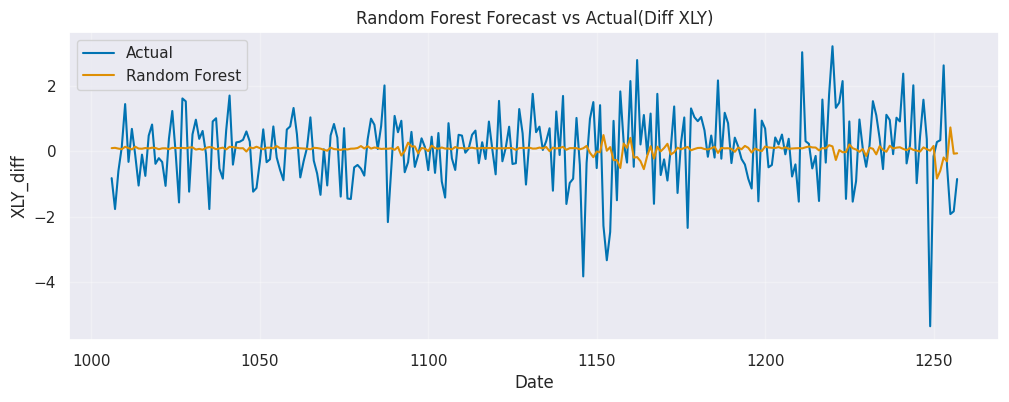

In [ ]:
tdf = pd.DataFrame({
    "Actual": full_data_model.loc[predictions_rf.index, "XLY_diff"],
    "Random Forest": predictions_rf["pred"]
})

tdf.plot(figsize=(12, 4))

plt.title("Random Forest Forecast vs Actual(Diff XLY)")
plt.xlabel("Date")
plt.ylabel("XLY_diff")
plt.grid(alpha=0.3)

plt.show()

### Feature Selection

In [40]:
from skforecast.feature_selection import select_features
from sklearn.feature_selection import RFECV

rf = RandomForestRegressor(**best_params)
selector = RFECV(estimator=rf, step=1, cv=5, scoring='neg_mean_absolute_error')

(
    selected_lags,
    selected_window_features,
    selected_exog,
    selected_calendar_features,
) = select_features(
    forecaster=forecaster,
    selector=selector,
    y=y,
    exog=exog,
    subsample=1.0,
    random_state=123,
    verbose=True,
)

Feature selection (RFECV)
-------------------------
Total number of records available: 1244
Total number of records used for feature selection: 1244
Number of features available: 20
    Lags            (n=14)
    Window features (n=0)
    Exog            (n=6)
    Calendar        (n=0)
Number of features selected: 15
    Lags            (n=12) : [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
    Window features (n=0) : []
    Exog            (n=3) : ['CL=F', 'GC=F', 'DX-Y.NYB']
    Calendar        (n=0) : []


### Re-run evaluation with selected features

In [41]:
forecaster = ForecasterRecursive(
    estimator=RandomForestRegressor(**best_params),
    lags=selected_lags
)

results_rf_fs, predictions_rf_fs = backtesting_forecaster(
                        forecaster=forecaster,
                        y=y,
                        exog=exog[selected_exog],
                        cv=cv,
                        metric=[root_mean_squared_error,
                                 'mean_absolute_error'],
                        n_jobs=1,
                     )
results_rf_fs.index = ["Random Forest (feature selection)"]
results_rf_fs

  0%|          | 0/252 [00:00<?, ?it/s]

,root_mean_squared_error,mean_absolute_error
Random Forest (feature selection),1.142787,0.877963


Recursive Feature Elimination with Cross Validation (RFECV) was used to determine if the number of lag and exogenous variables could be reduced to enhance the Random Forest model. Following the re-running of the model with selected features, the MAE value obtained was 0.8779 and the RMSE value is 1.1427. This was very similar to the overall performance of the full Random Forest model, with the full model performing slightly better overall. Thus, feature selection did not lead to a meaningful enhancement of the forecasting accuracy and the complete Random Forest model was kept as the most preferred machine learning model.

# Summary of All Models

In [42]:
tdf = pd.concat([results_lv, results_arima, results_rf, results_rf_fs], axis=0)
tdf

,root_mean_squared_error,mean_absolute_error
Last Value Baseline,1.570540,1.206563
ARIMA,1.119569,0.861978
Random Forest,1.138908,0.872376
Random Forest (feature selection),1.142787,0.877963


# 6. Conclusion

**Summary of key experimental results :**


*   The Last-Value Baseline model produced the lowest level of accuracy, This was expected because the model simply assumes that the next day's value will be the same as the previous day's value.
*  The forecasting results of the Random Forest models were quite similar to that of the AutoARIMA model.  While the Random Forest models achieved marginally lower MAE values, AutoARIMA produced the lowest RMSE.
*   Overall, all three advanced models substantially outperformed the Last-Value Baseline, with no single model showing a decisive advantage.
* The Random Forest model and the RF feature-selected model, however, showed little difference, suggesting that performing a feature selection did not significantly increase forecasting performance.

**Practical Insights and Recommendation:**


* The results indicate that the inclusion of historical price changes together with relevant macroeconomic variables can enhance forecast accuracy over what is achieved by using a simple baseline approach.
* The results of both models, AutoARIMA and Random Forest, showed forecast accuracy significantly higher than the baseline method Last-Value method, emphasizing the need to consider modelling temporal patterns in financial time series.
* Although Random Forest achieved the best overall performance, the improvement over AutoARIMA was relatively small. This indicates that the classical statistical models can be very competitive in predicting data from financial markets.
* In practical applications, the Random Forest model might be chosen if a slightly higher prediction accuracy is needed, whereas the AutoARIMA model is simpler and more interpretable, and performs close to the same as the Random Forest model. There was no significant improvement when feature selection was used so it is recommended that all the carefully selected predictors be kept for this dataset.





**Possible ways to improve the model:**


* Other explanatory variables like trading volume, volatility indices for the market or company-specific variables/ news sentiment on the economic news could be useful for the forecasting/forecasting models.
* Modelling the complex nonlinear relationships using more advanced machine learning and deep learning techniques like XGBoost, LightGBM or Long Short-Term Memory (LSTM) networks may be explored.
* Using alternative feature engineering designs, varying time horizons for forecasting and more extensive hyper-parameter optimisation can help to increase the accuracy and robustness of the model.






# Word Count

In [43]:
import nbformat

notebook_path = "/content/drive/MyDrive/Colab Notebooks/Business Forecasting/Assessment/250206546_Business_Forecasting.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = nbformat.read(f, as_version=4)

word_count = 0

for cell in nb.cells:
    if cell.cell_type == "markdown":
        text = cell["source"]

        # Remove common markdown formatting
        for symbol in ["#", "*", "`", "-", ">"]:
            text = text.replace(symbol, "")

        word_count += len(text.split())

print(f"Markdown Word Count: {word_count}")

Markdown Word Count: 1974


#Cite

Pekar, V. (2026). Business Forecasting. Lecture examples and exercises. (Version 1.0.0). URL: https://github.com/vpekar/bf


#Use of AI

Generative AI was used to assist in developing, debugging and refining the Python code used in this project, while all modelling decisions, analysis, interpretation and final submission remain my own work.